In [1]:
import torch
import time
import math
import copy
import random
import logging
import requests
import torchvision
import numpy as np
import matplotlib.pyplot as plt
import torch.optim as optim
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as transforms
from tqdm import tqdm
from torch.utils.data import DataLoader
from torchsummary import summary
from typing import Dict, Callable
from PIL import Image
import os
import pandas as pd
import wandb

assert torch.cuda.is_available()
device = torch.device("cuda")

In [2]:
class CIFARDataset(torch.utils.data.Dataset):
    def __init__(self, csv_file, image_dir, transform=None, labeled=True):
        self.data = pd.read_csv(csv_file)
        self.image_dir = image_dir
        self.transform = transform
        self.labeled = labeled

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        image = Image.open(os.path.join(self.image_dir, row["filename"])).convert("RGB")
        if self.transform:
            image = self.transform(image)
        if self.labeled:
            return image, int(row["label"])
        return image


class CIFAR:
    def __init__(self, batch_size=128, num_workers=2):
        self.root = "/kaggle/input/competitions/cifar-10-res-net-architecture-challenge-dl"
        self.batch_size = batch_size
        self.num_workers = num_workers
        self.train_loader, self.val_loader, self.test_loader = self.prepare_data()

    def prepare_data(self):
        transform_train = transforms.Compose([
            transforms.RandomCrop(32, padding=4),
            transforms.RandomHorizontalFlip(),
            transforms.AutoAugment(transforms.autoaugment.AutoAugmentPolicy.CIFAR10),
            # transforms.AutoAugment(),
            transforms.ToTensor(),
            transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
            transforms.RandomErasing(p=0.25, scale=(0.02, 0.1)),
        ])

        transform_test = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
        ])

        trainset = CIFARDataset(
            os.path.join(self.root, "train_labels.csv"),
            os.path.join(self.root, "train_images"),
            transform_train,
        )

        valset = CIFARDataset(
            os.path.join(self.root, "train_labels.csv"),
            os.path.join(self.root, "train_images"),
            transform_test,
        )

        testset = CIFARDataset(
            os.path.join(self.root, "test.csv"),
            os.path.join(self.root, "test_images"),
            transform_test,
            labeled=False,
        )

        train_size = int(0.9 * len(trainset))
        val_size = len(trainset) - train_size

        generator = torch.Generator().manual_seed(42)
        train_indices, val_indices = torch.utils.data.random_split(
            range(len(trainset)), [train_size, val_size], generator=generator
        )

        trainloader = torch.utils.data.DataLoader(
            # torch.utils.data.Subset(trainset, train_indices.indices),
            trainset,
            batch_size=self.batch_size, shuffle=True, num_workers=self.num_workers
        )

        valloader = torch.utils.data.DataLoader(
            torch.utils.data.Subset(valset, val_indices.indices),
            batch_size=self.batch_size, shuffle=False, num_workers=self.num_workers
        )

        testloader = torch.utils.data.DataLoader(
            testset, batch_size=self.batch_size, shuffle=False, num_workers=self.num_workers
        )

        return trainloader, valloader, testloader

In [3]:
class BasicBlock(nn.Module):
    """
    BasicBlock is the fundamental building block of ResNet.
    It consists of two 3x3 convolutional layers.
    If the input dimensions do not match the output dimensions,
    or the stride is not 1, a shortcut (identity mapping) is used to adjust dimensions.
    """

    expansion = 1

    def __init__(self, in_planes, planes, stride=1, kernel_size=3, shortcut_kernel_size=1):
        super(BasicBlock, self).__init__()
        # First convolution layer with batch normalization
        self.conv1 = nn.Conv2d(
            in_planes, planes, kernel_size=kernel_size, stride=stride, padding=1, bias=False
        )
        self.bn1 = nn.BatchNorm2d(planes)

        # Second convolution layer with batch normalization
        self.conv2 = nn.Conv2d(
            planes, planes, kernel_size=kernel_size, stride=1, padding=1, bias=False
        )
        self.bn2 = nn.BatchNorm2d(planes)

        # Shortcut connection (identity mapping)
        self.shortcut = nn.Sequential()
        if stride != 1 or in_planes != self.expansion * planes:
            self.shortcut = nn.Sequential(
                nn.Conv2d(
                    in_planes,
                    self.expansion * planes,
                    kernel_size=shortcut_kernel_size,
                    stride=stride,
                    bias=False,
                ),
                nn.BatchNorm2d(self.expansion * planes),
            )

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        shortcut_out = self.shortcut(x)
        out += shortcut_out
        out = F.relu(out)
        return out


class Bottleneck(nn.Module):
    """
    Bottleneck is the advanced building block used in deeper versions of ResNet (e.g., ResNet-50, ResNet-101).
    It consists of three layers: 1x1 conv, 3x3 conv, and another 1x1 conv.
    The purpose of the bottleneck is to reduce computation by compressing the dimensions before the 3x3 convolution.
    """

    expansion = 4

    def __init__(self, in_planes, planes, stride=1, kernel_size=3, shortcut_kernel_size=1):
        super(Bottleneck, self).__init__()
        # 1x1 convolution to reduce the number of input channels
        self.conv1 = nn.Conv2d(in_planes, planes, kernel_size=1, bias=False)
        self.bn1 = nn.BatchNorm2d(planes)

        # 3x3 convolution for main processing
        self.conv2 = nn.Conv2d(
            planes, planes, kernel_size=kernel_size, stride=stride, padding=1, bias=False
        )
        self.bn2 = nn.BatchNorm2d(planes)

        # 1x1 convolution to expand the number of output channels
        self.conv3 = nn.Conv2d(
            planes, self.expansion * planes, kernel_size=1, bias=False
        )
        self.bn3 = nn.BatchNorm2d(self.expansion * planes)

        # Shortcut connection
        self.shortcut = nn.Sequential()
        if stride != 1 or in_planes != self.expansion * planes:
            self.shortcut = nn.Sequential(
                nn.Conv2d(
                    in_planes,
                    self.expansion * planes,
                    kernel_size=shortcut_kernel_size,
                    stride=stride,
                    bias=False,
                ),
                nn.BatchNorm2d(self.expansion * planes),
            )

    def forward(self, x):
        # Forward pass through the bottleneck block (1x1 -> 3x3 -> 1x1)
        out = F.relu(self.bn1(self.conv1(x)))
        out = F.relu(self.bn2(self.conv2(out)))
        out = self.bn3(self.conv3(out))

        # Add the shortcut connection and pass through ReLU again
        out += self.shortcut(x)
        out = F.relu(out)
        return out


class ResNet(nn.Module):
    """
    ResNet class that builds the full ResNet architecture using the BasicBlock or Bottleneck block.
    The number of blocks and layers is determined by the `num_blocks` parameter.
    """

    def __init__(self, block, num_blocks, channels, kernel_size, shortcut_kernel_size, avg_pooling_size, num_classes=10):
        super(ResNet, self).__init__()
        self.in_planes = channels[0]
        self.kernel_size = kernel_size
        self.shortcut_kernel_size = shortcut_kernel_size
        self.avg_pooling_size = avg_pooling_size

        self.conv1 = nn.Conv2d(3, channels[0], kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(channels[0])

        # Create the subsequent layers of the network using the blocks
        self.layer1 = self._make_layer(block, channels[0], num_blocks[0], stride=1)
        self.layer2 = self._make_layer(block, channels[1], num_blocks[1], stride=2)
        self.layer3 = self._make_layer(block, channels[2], num_blocks[2], stride=2)
        self.layer4 = self._make_layer(block, channels[3], num_blocks[3], stride=2)

        # Final fully connected layer to classify the output
        self.linear = nn.Linear(channels[3] * block.expansion, num_classes)

    def _make_layer(self, block, planes, num_blocks, stride):
        """
        Creates a residual layer consisting of `num_blocks` residual blocks.
        The first block may have a stride > 1 to downsample the feature maps.
        """
        strides = [stride] + [1] * (num_blocks - 1)
        layers = []
        for stride in strides:
            layers.append(block(self.in_planes, planes, stride, self.kernel_size, self.shortcut_kernel_size))
            self.in_planes = planes * block.expansion
        return nn.Sequential(*layers)

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))

        out = self.layer1(out)
        out = self.layer2(out)
        out = self.layer3(out)
        out = self.layer4(out)
        out = F.avg_pool2d(out, self.avg_pooling_size)

        out = out.view(out.size(0), -1)
        out = self.linear(out)
        return out

def ResNet5M(blocks=[1, 1, 1, 1], channels=[64, 128, 256, 512], kernel_size=3, shortcut_kernel_size=1, avg_pooling_size=4):
    return ResNet(BasicBlock, blocks, channels, kernel_size, shortcut_kernel_size, avg_pooling_size)

# def ResNet18():
#     return ResNet(BasicBlock, [2, 2, 2, 2])

# def ResNet34():
#     return ResNet(BasicBlock, [3, 4, 6, 3])

# def ResNet50():
#     return ResNet(Bottleneck, [3, 4, 6, 3])

# def ResNet101():
#     return ResNet(Bottleneck, [3, 4, 23, 3])

# def ResNet152():
#     return ResNet(Bottleneck, [3, 8, 36, 3])

In [4]:
def cutmix_data(x, y, alpha=1.0, p=0.5):
    if np.random.rand() > p:
        return x, y, y, 1.0

    lam = np.random.beta(alpha, alpha)
    index = torch.randperm(x.size(0), device=x.device)

    h, w = x.size(2), x.size(3)

    cut_ratio = np.sqrt(1.0 - lam)
    cut_w = int(w * cut_ratio)
    cut_h = int(h * cut_ratio)

    cx = np.random.randint(w)
    cy = np.random.randint(h)

    x1 = np.clip(cx - cut_w // 2, 0, w)
    x2 = np.clip(cx + cut_w // 2, 0, w)
    y1 = np.clip(cy - cut_h // 2, 0, h)
    y2 = np.clip(cy + cut_h // 2, 0, h)

    x[:, :, y1:y2, x1:x2] = x[index, :, y1:y2, x1:x2]

    lam = 1 - ((x2 - x1) * (y2 - y1) / (w * h))

    return x, y, y[index], lam

In [5]:
def train(model, train_dataloader, val_dataloader, criterion, optimizer, epochs=10, device="cuda"):
    model = model.to(device)

    # warmup = torch.optim.lr_scheduler.LinearLR(
    #     optimizer,
    #     start_factor=0.1,
    #     end_factor=1.0,
    #     total_iters=5
    # )

    # cosine = torch.optim.lr_scheduler.CosineAnnealingLR(
    #     optimizer,
    #     T_max=epochs - 5,
    #     eta_min=1e-6
    # )
    
    # scheduler = torch.optim.lr_scheduler.SequentialLR(
    #     optimizer,
    #     schedulers=[warmup, cosine],
    #     milestones=[5]
    # )
    
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=epochs, eta_min=1e-6
    )

    wandb.init(project="deeplearning-resnet-cifar10", config=config)

    best_val_acc = 0.0

    for epoch in range(epochs):
        print(f"\nEpoch: {epoch+1}/{epochs}")
        model.train()
        train_loss = 0.0
        correct = 0
        total = 0

        with tqdm(total=len(train_dataloader), desc=f"Train Epoch {epoch+1}") as pbar:
            for batch_idx, (inputs, targets) in enumerate(train_dataloader):
                # # CutMix
                # inputs, targets = inputs.to(device), targets.to(device)
                # inputs, targets_a, targets_b, lam = cutmix_data(inputs, targets)

                # optimizer.zero_grad()
                # outputs = model(inputs)
                
                # loss = (
                #     lam * criterion(outputs, targets_a)
                #     + (1 - lam) * criterion(outputs, targets_b)
                # )
                # loss.backward()
                # optimizer.step()

                # Original:
                inputs, targets = inputs.to(device), targets.to(device)

                optimizer.zero_grad()
                outputs = model(inputs)
                loss = criterion(outputs, targets)
                loss.backward()
                optimizer.step()

                train_loss += loss.item()
                _, predicted = outputs.max(1)
                total += targets.size(0)
                correct += predicted.eq(targets).sum().item()

                pbar.set_postfix(
                    {
                        "Loss": f"{train_loss/(batch_idx+1):.3f}",
                        "Acc": f"{100.0 * correct / total:.3f}%",
                    }
                )
                pbar.update(1)

        epoch_loss = train_loss / len(train_dataloader)
        epoch_acc = 100.0 * correct / total

        val_acc = evaluate(model, val_dataloader, device)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), "best.pth")

        scheduler.step()

        wandb.log({
            "epoch": epoch + 1,
            "train/loss": epoch_loss,
            "train/accuracy": epoch_acc,
            "val/accuracy": val_acc,
            "lr": optimizer.param_groups[0]["lr"],
            "best_val_accuracy": best_val_acc,
        })

        print(
            f"Epoch [{epoch+1}/{epochs}] - Loss: {epoch_loss:.4f}, Accuracy: {epoch_acc:.2f}%"
        )

    wandb.finish()

    return model

In [6]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

def evaluate(model, test_dataloader, device="cuda", confusion=False) -> float:
    model = model.to(device)
    model.eval()

    correct = 0
    total = 0
    y_true, y_pred = [], []
    classes = [
        "airplane", "automobile", "bird", "cat", "deer",
        "dog", "frog", "horse", "ship", "truck"
    ]

    with torch.no_grad():
        for inputs, targets in tqdm(test_dataloader, desc="Evaluating", leave=False):
            # Original:
            # 
            # inputs, targets = inputs.to(device), targets.to(device)
            # y = model(inputs)
            # predicted = y.argmax(1)
            # y_true.extend(targets.cpu().numpy())
            # y_pred.extend(y.argmax(dim=1).cpu().numpy())

            # TTA:
            inputs, targets = inputs.to(device), targets.to(device)
            o1 = model(inputs)
            o2 = model(torch.flip(inputs, dims=[3]))
            o = (o1 + o2) / 2
            predicted = o.argmax(dim=1)
            y_true.extend(targets.cpu().numpy())
            y_pred.extend(predicted.cpu().numpy())
            
            total += targets.size(0)
            correct += predicted.eq(targets).sum().item()

    accuracy = 100. * correct / total

    print(f"Accuracy on the test set: {accuracy:.2f}%")

    if confusion:
        cm = confusion_matrix(y_true, y_pred)
    
        plt.figure(figsize=(10, 8))
        sns.heatmap(
            cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            xticklabels=[f"{i}: {c}" for i, c in enumerate(classes)],
            yticklabels=[f"{i}: {c}" for i, c in enumerate(classes)]
        )
        plt.xlabel("Predicted")
        plt.ylabel("Actual")
        plt.show()
    
        print(classification_report(
            y_true,
            y_pred,
            target_names=classes,
            digits=4
        ))
    
    return accuracy

In [7]:
def evaluate_submit(model, test_dataloader, submission_file="./submission.csv", device="cuda") -> float:
    model = model.to(device)
    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():
        with open(submission_file, "w", encoding="utf-8") as file:
            file.writelines(["id,label\n"])
            idx = 0
            for inputs in tqdm(test_dataloader, desc="Evaluating", leave=False):
                # inputs = inputs.to(device)
                # y = model(inputs)
                # preds = y.argmax(dim=1).cpu().tolist()

                inputs = inputs.to(device)
                o1 = model(inputs)
                o2 = model(torch.flip(inputs, dims=[3]))
                o = (o1 + o2) / 2
                preds= o.argmax(dim=1)

                file.writelines(f"{idx+i},{p}\n" for i, p in enumerate(preds))
                idx += len(preds)

In [8]:
%env WANDB_API_KEY=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

env: WANDB_API_KEY=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


In [ ]:
config = {
    "architecture": "ResNet5M",
    # "blocks": [1, 1, 1, 1],
    # "channels": [64, 128, 256, 512],
    "kernel_size": 3,
    "shortcut_kernel_size": 1,
    "avg_pooling_size": 4,
    "blocks": [2, 2, 2, 2],
    "channels": [64, 128, 232, 268],
    # "blocks": [2, 2, 2, 2],
    # "channels": [40, 80, 160, 320],
    # "blocks": [2, 4, 4, 3],
    # "channels": [32, 64, 128, 256],
    "batch_size": 128,
    "workers": 4,
    "epochs": 300,
    "optimizer": "SGD",
    "momentum": 0.9,
    "lr": 0.01,
    "weight_decay": 5e-04,
    "augmentation": "AutoAugment",
    "tta": True,
    "label_smoothing": 0.05
}

cifar_loader = CIFAR(batch_size=config["batch_size"], num_workers=config["workers"])
dataloader = {}
dataloader['train'], dataloader['val'], dataloader['test'] = cifar_loader.train_loader, cifar_loader.val_loader, cifar_loader.test_loader

model = ResNet5M(blocks=config["blocks"], channels=config["channels"]).to(device)
summary(model, (3, 32, 32))
num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
assert num_params <= 5_000_000

# if torch.cuda.device_count() > 1:
#     model = nn.DataParallel(model)
criterion = nn.CrossEntropyLoss(label_smoothing=config["label_smoothing"])
# optimizer = optim.AdamW(model.parameters(), lr=config["lr"], weight_decay=config["weight_decay"])
optimizer = optim.SGD(model.parameters(), lr=config["lr"], momentum=config["momentum"], weight_decay=config["weight_decay"])
train(
    model=model,
    train_dataloader=dataloader['train'],
    # val_dataloader=dataloader['val'],
    val_dataloader=CIFAROriginal(batch_size=128, num_workers=4).test_loader,
    criterion=criterion,
    optimizer=optimizer,
    epochs=config["epochs"],
    device="cuda"
)

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 32, 32]           1,728
       BatchNorm2d-2           [-1, 64, 32, 32]             128
            Conv2d-3           [-1, 64, 32, 32]          36,864
       BatchNorm2d-4           [-1, 64, 32, 32]             128
            Conv2d-5           [-1, 64, 32, 32]          36,864
       BatchNorm2d-6           [-1, 64, 32, 32]             128
        BasicBlock-7           [-1, 64, 32, 32]               0
            Conv2d-8           [-1, 64, 32, 32]          36,864
       BatchNorm2d-9           [-1, 64, 32, 32]             128
           Conv2d-10           [-1, 64, 32, 32]          36,864
      BatchNorm2d-11           [-1, 64, 32, 32]             128
       BasicBlock-12           [-1, 64, 32, 32]               0
           Conv2d-13          [-1, 128, 16, 16]          73,728
      BatchNorm2d-14          [-1, 128,


Epoch: 1/300


Train Epoch 1: 100%|██████████| 391/391 [00:37<00:00, 10.34it/s, Loss=1.798, Acc=36.896%]


Accuracy on the test set: 59.05%
Epoch [1/300] - Loss: 1.7978, Accuracy: 36.90%

Epoch: 2/300


Train Epoch 2: 100%|██████████| 391/391 [00:37<00:00, 10.39it/s, Loss=1.370, Acc=55.812%]


Accuracy on the test set: 66.41%
Epoch [2/300] - Loss: 1.3697, Accuracy: 55.81%

Epoch: 3/300


... (259 outputs left out)

Accuracy on the test set: 94.54%
Epoch [132/300] - Loss: 0.4327, Accuracy: 94.13%

Epoch: 133/300


Train Epoch 133: 100%|██████████| 391/391 [00:37<00:00, 10.30it/s, Loss=0.430, Acc=94.290%]


Accuracy on the test set: 94.45%
Epoch [133/300] - Loss: 0.4297, Accuracy: 94.29%

Epoch: 134/300


Train Epoch 134:  41%|████      | 159/391 [00:15<00:22, 10.49it/s, Loss=0.423, Acc=94.585%]

Accuracy on the test set: 100.00%


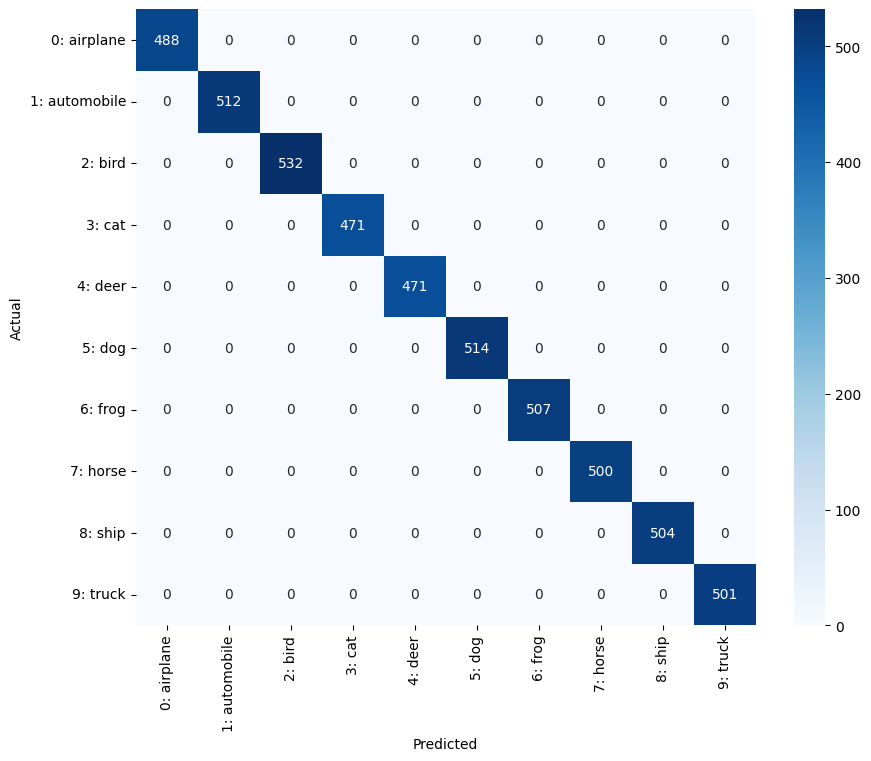

              precision    recall  f1-score   support

    airplane     1.0000    1.0000    1.0000       488
  automobile     1.0000    1.0000    1.0000       512
        bird     1.0000    1.0000    1.0000       532
         cat     1.0000    1.0000    1.0000       471
        deer     1.0000    1.0000    1.0000       471
         dog     1.0000    1.0000    1.0000       514
        frog     1.0000    1.0000    1.0000       507
       horse     1.0000    1.0000    1.0000       500
        ship     1.0000    1.0000    1.0000       504
       truck     1.0000    1.0000    1.0000       501

    accuracy                         1.0000      5000
   macro avg     1.0000    1.0000    1.0000      5000
weighted avg     1.0000    1.0000    1.0000      5000



100.0

In [28]:
evaluate(
    model=model,
    test_dataloader=dataloader['val'],
    device="cuda",
    confusion=True
)

Accuracy on the test set: 10.00%


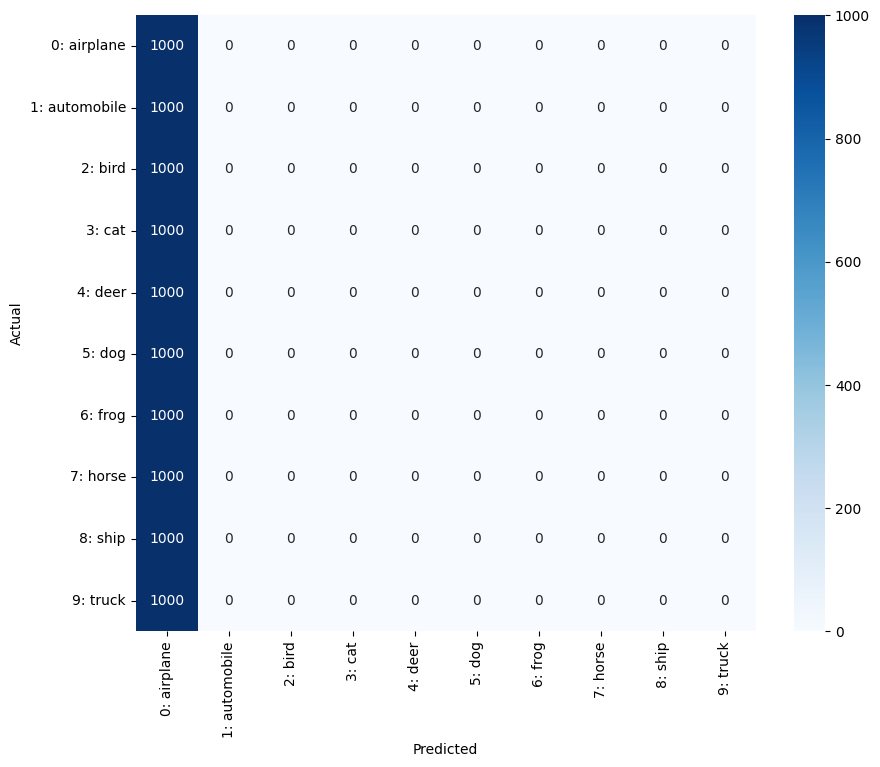

              precision    recall  f1-score   support

    airplane     0.1000    1.0000    0.1818      1000
  automobile     0.0000    0.0000    0.0000      1000
        bird     0.0000    0.0000    0.0000      1000
         cat     0.0000    0.0000    0.0000      1000
        deer     0.0000    0.0000    0.0000      1000
         dog     0.0000    0.0000    0.0000      1000
        frog     0.0000    0.0000    0.0000      1000
       horse     0.0000    0.0000    0.0000      1000
        ship     0.0000    0.0000    0.0000      1000
       truck     0.0000    0.0000    0.0000      1000

    accuracy                         0.1000     10000
   macro avg     0.0100    0.1000    0.0182     10000
weighted avg     0.0100    0.1000    0.0182     10000



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


10.0

In [10]:
class CIFAROriginal:
    def __init__(self, batch_size=128, num_workers=2):
        self.batch_size = batch_size
        self.num_workers = num_workers
        self.test_loader = self.prepare_data()

    def prepare_data(self):
        transform_test = transforms.Compose(
            [
                transforms.ToTensor(),
                transforms.Normalize(
                    (0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)
                ),
            ]
        )

        testset = torchvision.datasets.CIFAR10(
            root="./data_original", train=False, download=True, transform=transform_test
        )
        testloader = torch.utils.data.DataLoader(
            testset, batch_size=128, shuffle=False, num_workers=self.num_workers
        )

        return testloader

cifar_original = CIFAROriginal(batch_size=32, num_workers=4)
dataloader_test_original = cifar_original.test_loader
evaluate(
    model=model,
    test_dataloader=dataloader_test_original,
    device="cuda",
    confusion=True
)

In [31]:
!rm submission.csv
evaluate_submit(
    model=model,
    test_dataloader=dataloader['test'],
    device="cuda"
)

rm: cannot remove 'submission.csv': No such file or directory


In [22]:
loaded_model = ResNet5M(blocks=config["blocks"], channels=config["channels"])

state_dict = torch.load("best-87.pth", map_location=device, weights_only=True)
state_dict = {k.replace("module.", "", 1): v for k, v in state_dict.items()}

loaded_model.load_state_dict(state_dict)
loaded_model = loaded_model.to(device)

# evaluate(loaded_model, CIFAROriginal(batch_size=32, num_workers=4).test_loader, device)

evaluate_submit(
    model=loaded_model,
    test_dataloader=dataloader['test'],
    device="cuda"
)

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.
wandb: Currently logged in as: ricardotk002 (dl-resnet-2026) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin



Epoch: 1/5


Train Epoch 1: 100%|██████████| 40/40 [00:08<00:00,  4.57it/s, Loss=2.440, Acc=10.700%]


Accuracy on the test set: 10.42%
Epoch [1/5] - Loss: 2.4395, Accuracy: 10.70%

Epoch: 2/5


Train Epoch 2: 100%|██████████| 40/40 [00:04<00:00,  8.40it/s, Loss=2.440, Acc=10.700%]


Accuracy on the test set: 10.52%
Epoch [2/5] - Loss: 2.4395, Accuracy: 10.70%

Epoch: 3/5


... (4 outputs left out)

Train Epoch 5: 100%|██████████| 40/40 [00:04<00:00,  9.27it/s, Loss=2.440, Acc=10.700%]
                                                           

Accuracy on the test set: 10.50%
Epoch [5/5] - Loss: 2.4395, Accuracy: 10.70%


best_val_accuracy,▁████
epoch,▁▃▅▆█
lr,█▆▄▂▁
train/accuracy,▁▁▁▁▁
train/loss,▁▁▁▁▁
val/accuracy,▁█▇▇▇
best_val_accuracy,10.52
epoch,5
lr,0.0
train/accuracy,10.7
train/loss,2.43951


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (shortcut): Sequential()
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=